In [1]:
from sklearn.datasets import load_iris
import pandas as pd

# Load Iris dataset from scikit-learn
iris = load_iris()

# Convert to DataFrame
df = pd.DataFrame(
    iris.data,
    columns=iris.feature_names
)

# Add flower species names
df["species"] = [
    iris.target_names[i]
    for i in iris.target
]

# Save dataset as CSV
df.to_csv("iris.csv", index=False)

print("Iris dataset saved successfully!")
print("Shape:", df.shape)
display(df.head())

Iris dataset saved successfully!
Shape: (150, 5)


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [4]:
df.shape

(150, 5)

In [5]:
df = pd.read_csv("iris.csv")

print("First five records:")
display(df.head())

print("Last five records:")
display(df.tail())

First five records:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


Last five records:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
145,6.7,3.0,5.2,2.3,virginica
146,6.3,2.5,5.0,1.9,virginica
147,6.5,3.0,5.2,2.0,virginica
148,6.2,3.4,5.4,2.3,virginica
149,5.9,3.0,5.1,1.8,virginica


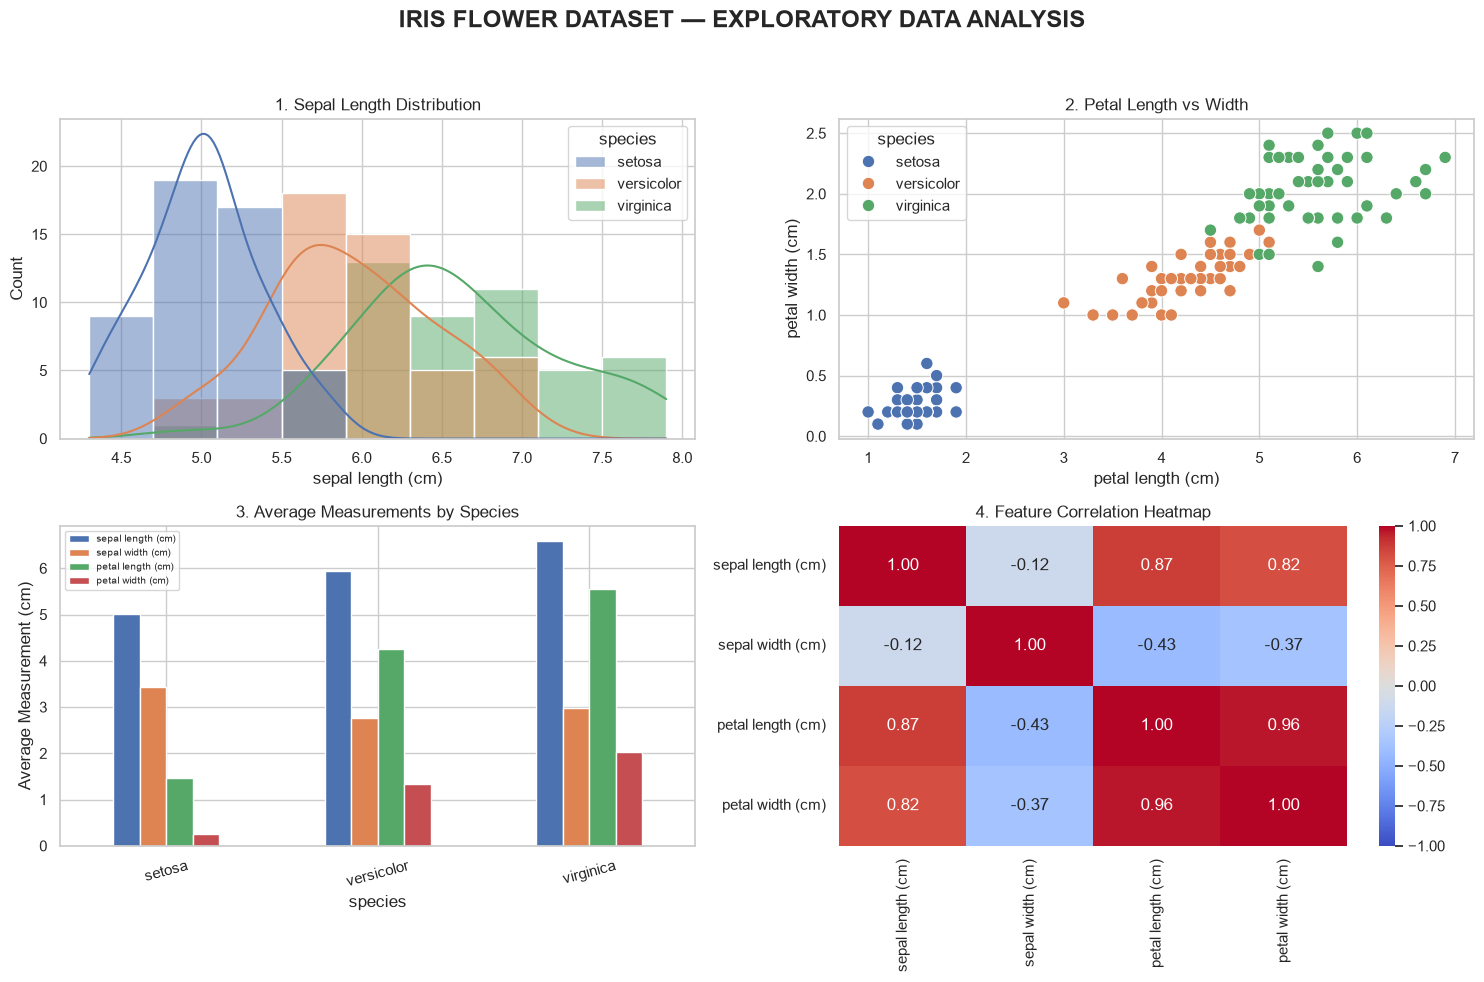

In [7]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load the CSV file
df = pd.read_csv("iris.csv")

# Numerical feature columns
features = [
    "sepal length (cm)",
    "sepal width (cm)",
    "petal length (cm)",
    "petal width (cm)"
]

sns.set_theme(style="whitegrid")

fig, axes = plt.subplots(2, 2, figsize=(15, 10))

fig.suptitle(
    "IRIS FLOWER DATASET — EXPLORATORY DATA ANALYSIS",
    fontsize=17,
    fontweight="bold"
)

# 1. Sepal length distribution
sns.histplot(
    data=df,
    x="sepal length (cm)",
    hue="species",
    kde=True,
    ax=axes[0, 0]
)
axes[0, 0].set_title("1. Sepal Length Distribution")

# 2. Petal length vs petal width
sns.scatterplot(
    data=df,
    x="petal length (cm)",
    y="petal width (cm)",
    hue="species",
    s=80,
    ax=axes[0, 1]
)
axes[0, 1].set_title("2. Petal Length vs Width")

# 3. Compare average measurements by species
species_means = df.groupby("species")[features].mean()
species_means.plot(
    kind="bar",
    ax=axes[1, 0]
)
axes[1, 0].set_title("3. Average Measurements by Species")
axes[1, 0].set_ylabel("Average Measurement (cm)")
axes[1, 0].tick_params(axis="x", rotation=15)
axes[1, 0].legend(fontsize=7)

# 4. Correlation heatmap
correlation = df[features].corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1,
    ax=axes[1, 1]
)
axes[1, 1].set_title("4. Feature Correlation Heatmap")

plt.tight_layout(rect=[0, 0, 1, 0.95])

# Save a high-quality image for LinkedIn
plt.savefig(
    "iris_visualization_dashboard.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()